In [1]:
import sys
sys.path.append('../src/')
from xpcs import *
from plotting import *
from autocorrelations import *
import cv2
from scipy.special import erfinv
import pyopencl as cl
from pathlib import Path
import json
from scipy.fft import fft, ifft, fftfreq
import matplotlib.ticker as ticker

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap

from scipy.interpolate import interp1d
from scipy.signal import detrend


%matplotlib widget

In [ ]:
### User Defined
### This should be the only thing that needs to defined
#from notebooks.xrd_112023 import nipy_uc


CONFIG_FILE_NAME = "../configs/config_NPS_example.json" #"config_B10_2_A7_data_071525.json"


### Scan In Config You Want to PreProcess ### 
Scan = 65

# nipy_spectral through the red, stopping before the gray-white tip
_nipy = plt.colormaps['nipy_spectral'](np.linspace(0, 0.94, 256))
nipy_spectral_nowhite = LinearSegmentedColormap.from_list('nipy_spectral_nowhite', _nipy, N=256)

CMAP = nipy_spectral_nowhite
#File Type
File_Type = "processed"



In [3]:
### Figure Settings ###

plt.rcParams['font.sans-serif'] = ['Helvetica']

legend_ax_font = 12
ax_label_font = 16
ax_title_font = 18

minor_tick_length = 6
major_tick_length = 9
minor_tick_width = 0.75
major_tick_width = 1.0

fig_size = (8,5)

nps_custom = LinearSegmentedColormap.from_list(
  'nps_custom', [
    (0.00, '#000000'),
    (0.12, '#342c7a'),
    (0.25, '#a43479'),
    (0.55, '#d74444'),
    (0.78, '#f3de80'),
    (1.00, '#ffffff'),
], N=256
)

In [4]:
config_file = Path(CONFIG_FILE_NAME)

# Define the path to the configuration file

# Open and load the JSON configuration file
with open(config_file, "r") as file:
    config = json.load(file)
    #json_str = json.loads(jsonString, strict=False)

### Output Directory ###
figure_path = config_file.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)

base_path = Path(config.get("Base")) 
results_path = Path(config.get("Processed"))
file = base_path / Path(config.get(f"{Scan}")) / results_path / Path(config.get(f"{Scan}_{File_Type}"))

with h5py.File(file, 'r') as DATA:
    det = DATA['data/det'][:]
    Qy = DATA['pre_processing/Qy'][:]
    Qx = DATA['pre_processing/Qx'][:]
    fs = DATA['experimental_parameters/frame_spacing'][:][0]
    nf = DATA['experimental_parameters/nFrames'][:][0]


In [5]:
Q = np.sqrt((Qx-Qx[Qx.shape[0]//2,Qx.shape[1]//2])**2 + (Qy-Qy[Qy.shape[0]//2,Qy.shape[1]//2])**2)

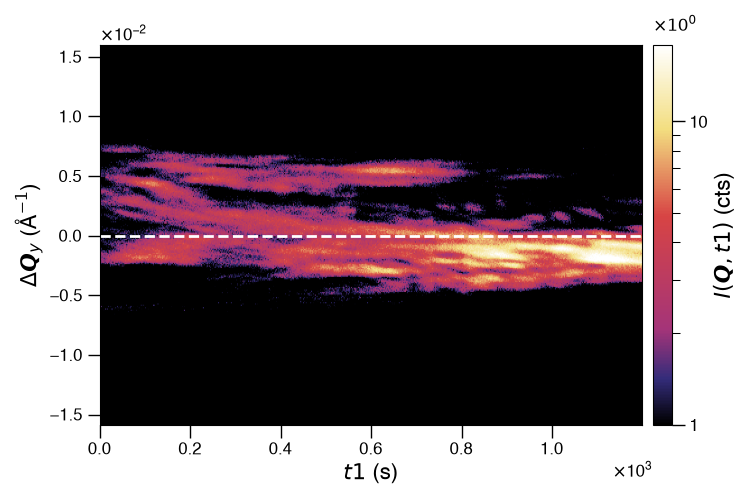

In [6]:
vertical_width = 300
cx = det.shape[2] // 2
cy = det.shape[1] // 2
y0 = cy - vertical_width // 2
y1 = cy + vertical_width // 2
waterfall = (det[:, y0:y1, cx]/det[:, y0:y1, cx].mean() + 1e-5).T
dQ = np.flip(Qy[y0:y1, cx] - Qy[cy, cx])
fs_val = float(fs) if hasattr(fs, '__len__') and len(fs) == 1 else fs
nf_val = int(nf) if hasattr(nf, '__len__') and len(nf) == 1 else nf
t_axis = np.arange(0, fs_val * nf_val, fs_val)[:waterfall.shape[1]]
if len(t_axis) < waterfall.shape[1]:
    t_axis = np.pad(t_axis, (0, waterfall.shape[1] - len(t_axis)),
                    constant_values=t_axis[-1] + fs_val)
fig, ax = plt.subplots(figsize=(7.5,5))
im = ax.imshow(
    waterfall,
    cmap=nps_custom,
    norm=LogNorm(vmin=1, vmax=17.823522280361132),
    aspect='auto',
    extent=[t_axis[0], t_axis[-1], dQ[0], dQ[-1]],
)
ax.set_xlabel(r"$t1$ (s)", fontsize=ax_label_font)
ax.set_ylabel(r"$\Delta \boldsymbol{Q}_y$ (Å$^{-1}$)", fontsize=ax_label_font)
ax.axhline(0, color='w', lw=2, ls='--')

ax.xaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax.xaxis.get_offset_text().set_fontsize(legend_ax_font)  # Adjust font size if needed
ax.xaxis.get_offset_text().set_position((1.02, 0))  # Move offset label slightly

ax.yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax.yaxis.get_offset_text().set_fontsize(legend_ax_font)
ax.yaxis.get_offset_text().set_position((0, 1.02))  # Move offset label slightly

ax.ticklabel_format(axis='both', style='sci', scilimits=(0, 0))  # Force scientific notation


ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)



cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02,
    fraction=0.035,
    shrink=1.0,
)
cbar.set_label(r'$I(\boldsymbol{Q},t1)$ (cts)', fontsize=ax_label_font)
cbar.ax.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font)
cbar.ax.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=legend_ax_font)
format_log_colorbar(cbar, labelsize=legend_ax_font)




plt.tight_layout()

fig.savefig(figure_path / f"waterfall_{Scan}.pdf",format="pdf",dpi=300,bbox_inches="tight",metadata={'Creator': ''})

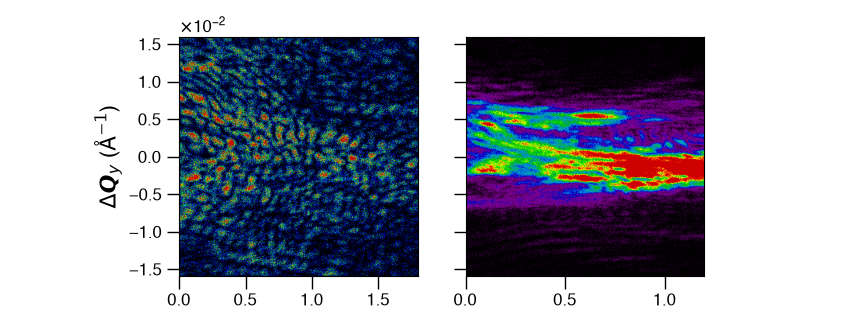

In [7]:
# Combined waterfall: equal square panels (longer scan squashed to fit)
Scans = [219, 65]
labels = np.array(['(BM)-"$c$"-Na$_3$PS$_4$','(HT)-$t$-Na$_3$PS$_4$'])
colors = np.array(['#074a54', 'k'])
waterfall_vmin = 0
waterfall_vmax = 5.5# 17.823522280361132
#waterfall_norm = LogNorm(vmin=waterfall_vmin, vmax=waterfall_vmax)
panels = []

for s in Scans:
    config_file = Path(CONFIG_FILE_NAME)
    with open(config_file, "r") as file:
        config = json.load(file)

    base_path = Path(config.get("Base"))
    results_path = Path(config.get("Processed"))
    file = base_path / Path(config.get(f"{s}")) / results_path / Path(config.get(f"{s}_{File_Type}"))

    with h5py.File(file, 'r') as DATA:
        det = DATA['data/det'][:]
        Qy = DATA['pre_processing/Qy'][:]
        fs = DATA['experimental_parameters/frame_spacing'][:][0]
        nf = DATA['experimental_parameters/nFrames'][:][0]

    vertical_width = 300
    cx = det.shape[2] // 2
    cy = det.shape[1] // 2
    y0 = cy - vertical_width // 2
    y1 = cy + vertical_width // 2
    waterfall = (det[:, y0:y1, cx] / det[:, y0:y1, cx].mean() + 1e-5).T
    dQ = np.flip(Qy[y0:y1, cx] - Qy[cy, cx])

    fs_val = float(fs) if hasattr(fs, '__len__') and len(fs) == 1 else fs
    nf_val = int(nf) if hasattr(nf, '__len__') and len(nf) == 1 else nf
    t_axis = np.arange(0, fs_val * nf_val, fs_val)[:waterfall.shape[1]]
    if len(t_axis) < waterfall.shape[1]:
        t_axis = np.pad(
            t_axis, (0, waterfall.shape[1] - len(t_axis)),
            constant_values=t_axis[-1] + fs_val,
        )

    panels.append({
        "scan": s,
        "waterfall": waterfall,
        "dQ": dQ,
        "t_axis": t_axis,
    })

fig, ax = plt.subplots(1, 2, figsize=(8.62,3.1))

mappable = None
for i, panel in enumerate(panels):
    s = panel["scan"]
    t_axis = panel["t_axis"]
    dQ = panel["dQ"]
    mappable = ax[i].imshow(
        panel["waterfall"],
        cmap=CMAP,
        vmin=waterfall_vmin,
        vmax=waterfall_vmax,
        aspect="auto",
        extent=[t_axis[0], t_axis[-1], dQ[0], dQ[-1]],
    )
    ax[i].set_box_aspect(1)  # square panel; aspect="auto" squashes longer scan to fit

    ax[i].set_xlabel(r"$t_1$ (s)", fontsize=ax_label_font)
    if s == 219:
        ax[i].set_ylabel(r"$\Delta \boldsymbol{Q}_y$ (Å$^{-1}$)", fontsize=ax_label_font)
    #ax[i].axhline(0, color="w", lw=2, ls="--")
    #ax[i].set_title(labels[i], color=colors[i], fontsize=ax_title_font, fontweight="bold")

    ax[i].xaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
    ax[i].xaxis.get_offset_text().set_fontsize(legend_ax_font)
    ax[i].xaxis.get_offset_text().set_position((1.02, 0))

    ax[i].yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
    ax[i].yaxis.get_offset_text().set_fontsize(legend_ax_font)
    ax[i].yaxis.get_offset_text().set_position((0, 1.02))

    ax[i].ticklabel_format(axis="both", style="sci", scilimits=(0, 0))
    ax[i].tick_params(
        which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font
    )
    ax[i].tick_params(
        which="minor", length=minor_tick_length, width=minor_tick_width, labelsize=legend_ax_font
    )
    if i == 1:
        ax[i].tick_params(which="both", labelbottom=True, labelleft=False)
        #ax[i].xaxis.offsetText.set_visible(False)
        ax[i].yaxis.offsetText.set_visible(False)
fig.subplots_adjust(wspace=-0.25)
#cbar = fig.colorbar(mappable, ax=ax,pad=0.0267, fraction=0.05, shrink=1.0)# pad=0.02, fraction=0.035, shrink=0.85)
#cbar.set_label(r"$I(\boldsymbol{Q},t1)$ (cts)", fontsize=ax_label_font)
#cbar.ax.tick_params(
#    which="major", length=major_tick_length, width=major_tick_width, labelsize=legend_ax_font
#)
#cbar.ax.tick_params(
#    which="minor", length=minor_tick_length, width=minor_tick_width, labelsize=legend_ax_font
#)
#format_log_colorbar(cbar, labelsize=legend_ax_font)

fig.savefig(
    figure_path / "waterfall_combined.pdf",
    format="pdf", dpi=300, bbox_inches="tight", metadata={"Creator": ""},
)

